In [ ]:
# Collect the data
import kagglehub

# Download latest version
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Path to dataset files:", path)

In [4]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:

DATASET_PATH = os.path.join(path, 'WA_Fn-UseC_-Telco-Customer-Churn.csv')

df = pd.read_csv(DATASET_PATH)

In [5]:

ROOT_DIR = os.path.dirname(os.getcwd())

DATA_DIR = os.path.join(ROOT_DIR, 'data')
DATA_DIR_RAW = os.path.join(DATA_DIR, 'raw')
DATA_DIR_PROCESSED = os.path.join(DATA_DIR, 'processed')

DATASET_NAME_V1 = f"{DATA_DIR_RAW}/churnv1.csv"

# df.to_csv(DATASET_NAME_V1, index=True)



#### Load the dataset

In [6]:
df = pd.read_csv(DATASET_NAME_V1)

df.sample(5)

,Unnamed: 0,index,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
6501,6501,6501,4753-PADAS,Female,0,Yes,No,67,Yes,Yes,...,Yes,No,Yes,Yes,One year,Yes,Bank transfer (automatic),105.70,6816.95,No
76,76,76,6416-JNVRK,Female,0,No,No,46,Yes,No,...,No,No,No,Yes,One year,No,Credit card (automatic),55.65,2688.85,No
3224,3224,3224,4013-UBXWQ,Female,0,No,No,7,Yes,Yes,...,No,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,74.65,521.1,Yes
6858,6858,6858,2685-SREOM,Female,0,Yes,Yes,25,Yes,Yes,...,Yes,No,No,Yes,Month-to-month,Yes,Electronic check,89.10,2368.4,Yes
6740,6740,6740,7957-RYHQD,Female,1,No,No,40,Yes,No,...,No,No,No,No,Month-to-month,Yes,Credit card (automatic),79.20,3233.85,Yes


#### Dataset info

In [ ]:
# df = df.rename(columns={'Inedx': 'Index'})
# df.drop(columns=['Unnamed: 0'], inplace=True)
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   index             7043 non-null   int64  
 1   customerID        7043 non-null   object 
 2   gender            7043 non-null   object 
 3   SeniorCitizen     7043 non-null   int64  
 4   Partner           7043 non-null   object 
 5   Dependents        7043 non-null   object 
 6   tenure            7043 non-null   int64  
 7   PhoneService      7043 non-null   object 
 8   MultipleLines     7043 non-null   object 
 9   InternetService   7043 non-null   object 
 10  OnlineSecurity    7043 non-null   object 
 11  OnlineBackup      7043 non-null   object 
 12  DeviceProtection  7043 non-null   object 
 13  TechSupport       7043 non-null   object 
 14  StreamingTV       7043 non-null   object 
 15  StreamingMovies   7043 non-null   object 
 16  Contract          7043 non-null   object 


### Data Exploration

### Target 

__Churn__ Column is our target column and here we need to find the customer/individual who can leave service within a specific period of time.

>__Churn prediction is the use of data, statistics, and machine learning to forecast which customers or subscribers are likely to stop using a product or cancel a service within a specific time frame__

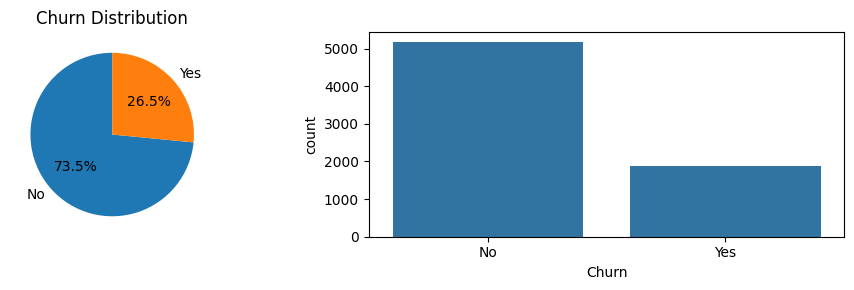

In [8]:
churn_counts = df['Churn'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(10, 3))

axes[0].pie(churn_counts, 
            labels=churn_counts.index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0].set_title('Churn Distribution')

sns.countplot(data=df, x='Churn', ax=axes[1])
fig.tight_layout()
plt.show()

__Separate Feature and target columns from the dataset__

In [9]:
features = df.drop(columns=['Churn', 'index', 'customerID'])
target = df['Churn']

__Gender:__ Whether the customer is a male or a female

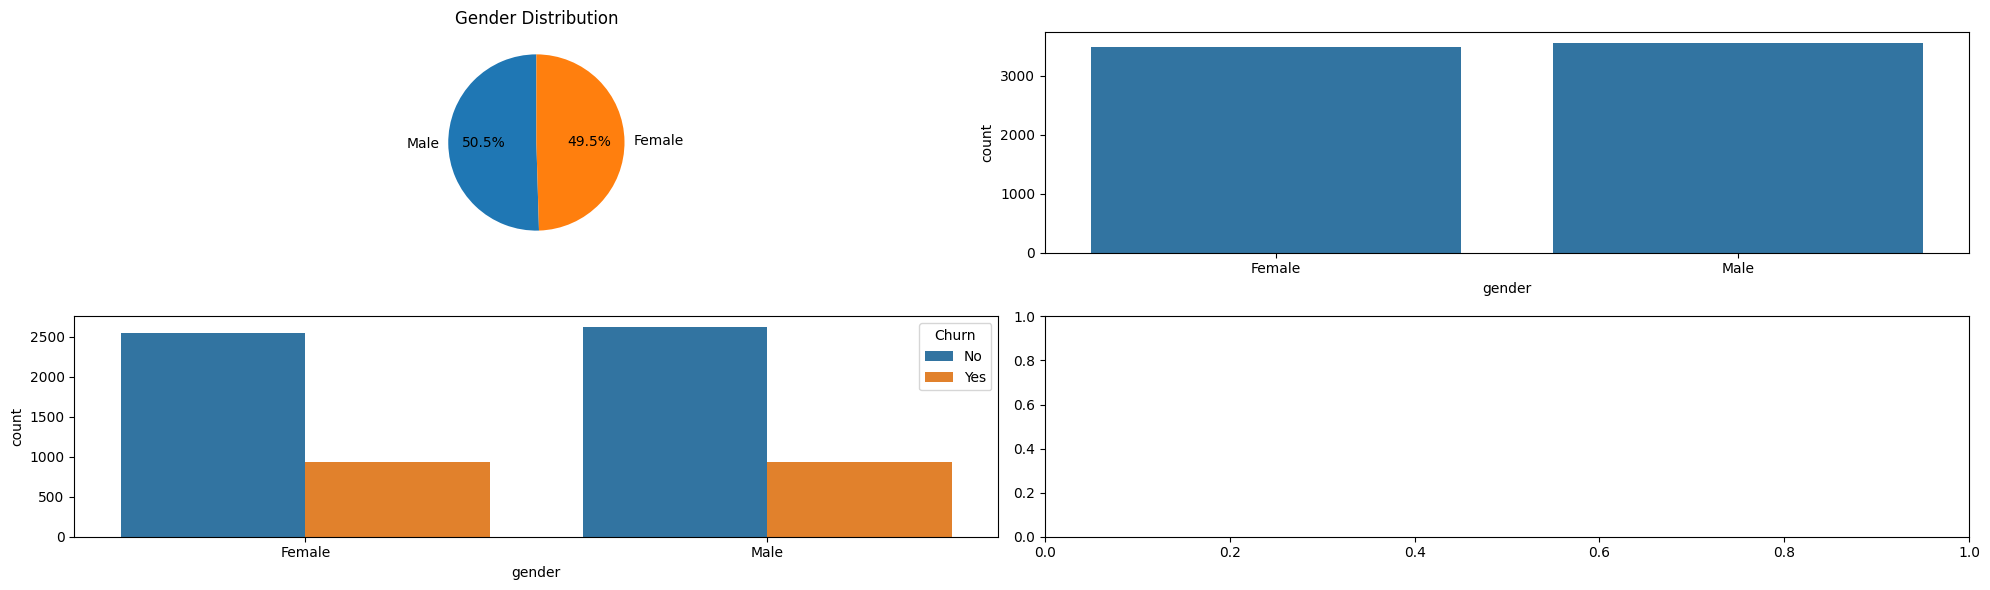

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['gender'].value_counts(), 
            labels=features['gender'].value_counts().index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0, 0].set_title('Gender Distribution')

sns.countplot(data=features, x='gender', ax=axes[0, 1])
sns.countplot(data=features, x='gender', hue=target, ax=axes[1, 0])

fig.tight_layout()

plt.show()

__We have 50.5% of male and 49.5% of female here and in counts there are 3555 male and 3488 female customers.__

In [11]:
print(features['SeniorCitizen'].value_counts())

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64


In `SeniorCitizen` columns we have only value 0 and 1. That means `boolean` value is that this __individual__ is __SeniorCitizen__ or not.

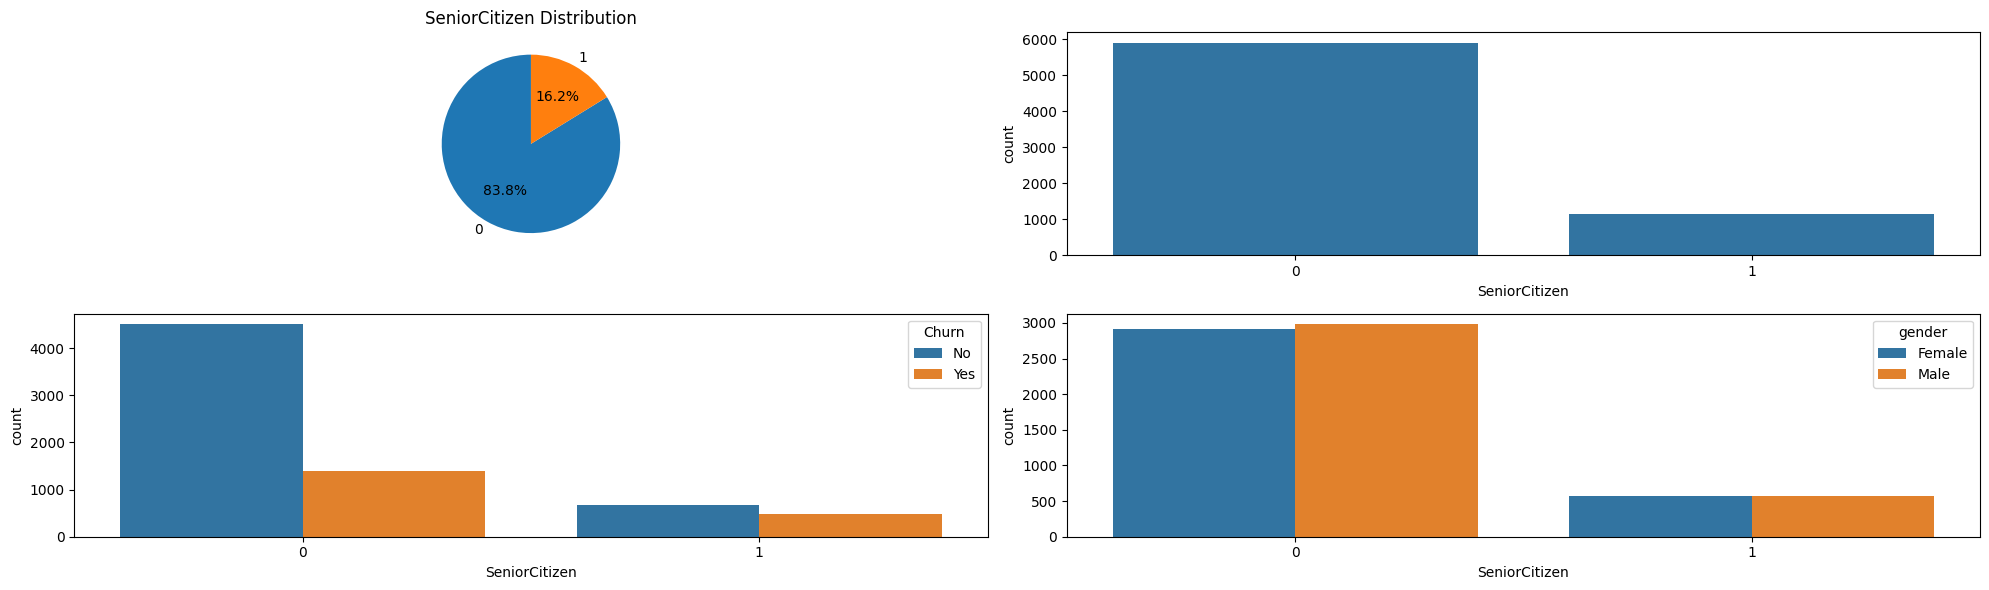

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['SeniorCitizen'].value_counts(), 
            labels=features['SeniorCitizen'].value_counts().index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0, 0].set_title('SeniorCitizen Distribution')

sns.countplot(data=features, x='SeniorCitizen', ax=axes[0, 1])
sns.countplot(data=features, x='SeniorCitizen', hue=target, ax=axes[1, 0])
sns.countplot(data=features, x='SeniorCitizen', hue='gender', ax=axes[1, 1])


fig.tight_layout()

plt.show()

In [ ]:
features['Partner'].value_counts()

Partner
No     3641
Yes    3402
Name: count, dtype: int64

__Partner:__ Whether the customer has a partner or not (Yes, No)

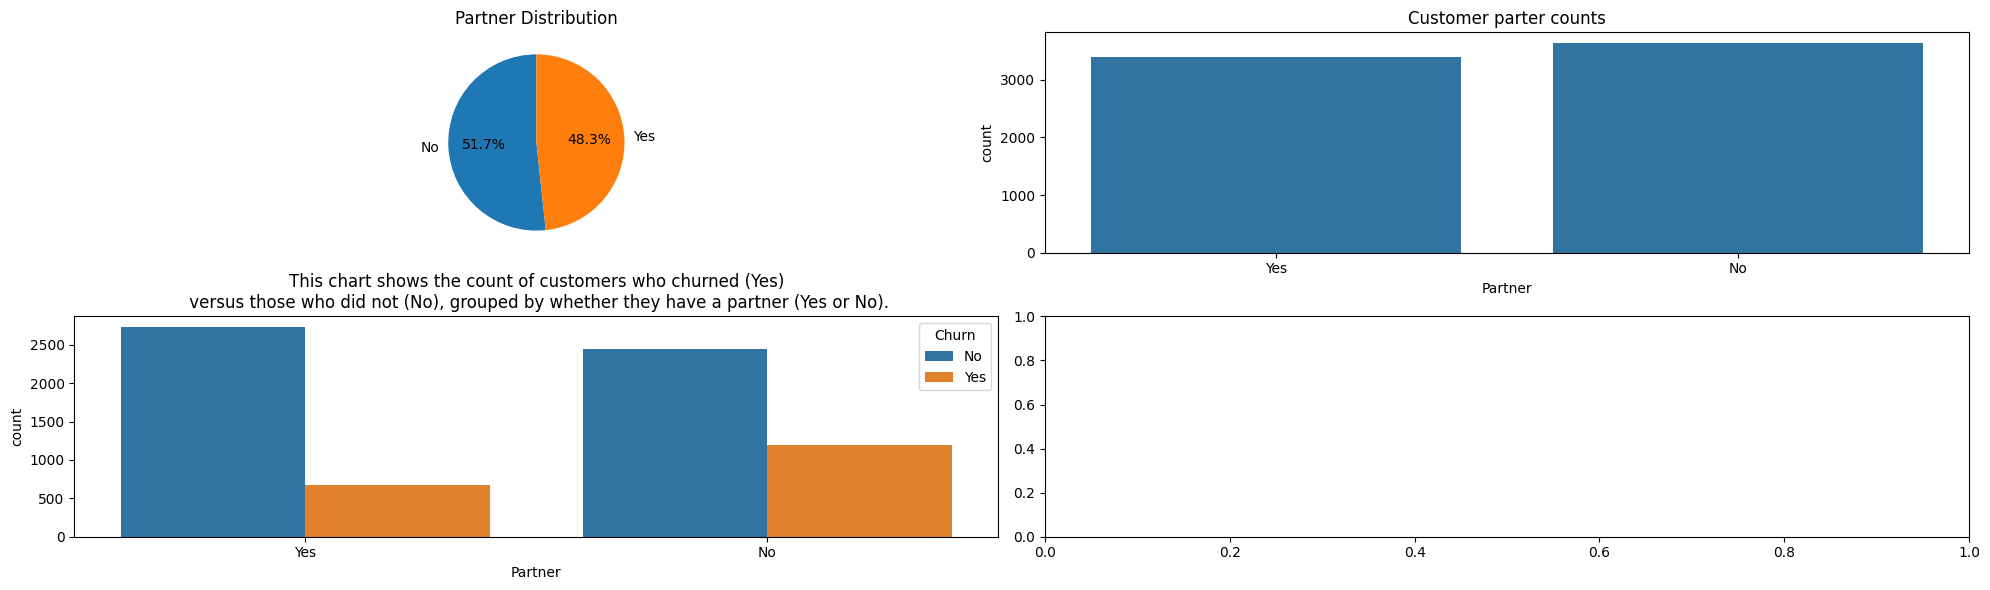

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['Partner'].value_counts(), 
            labels=features['Partner'].value_counts().index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0, 0].set_title('Partner Distribution')

sns.countplot(data=features, x='Partner', ax=axes[0, 1])
axes[0, 1].set_title('Customer parter counts')

sns.countplot(data=features, x='Partner', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('This chart shows the count of customers who churned (Yes)\n versus those who did not (No), grouped by whether they have a partner (Yes or No).')
fig.tight_layout()

plt.show()

In dataset there are 48.3% of individual who have __parterns__ and 51.7% who dont have __Parterns__

Customers with a __Partner__ (Yes on the left): Roughly 2,700 stayed (Churn = No), while around 650 churned (Churn = Yes) - a relatively low churn rate.
Customers without a __Partner__ (No on the right): Roughly 2,400 stayed (Churn = No), while about 1,200 churned (Churn = Yes) — nearly double the number of churns compared to customers with partners.

<br><br>
__Dependents:__ Whether the customer has dependents or not (Yes, No)

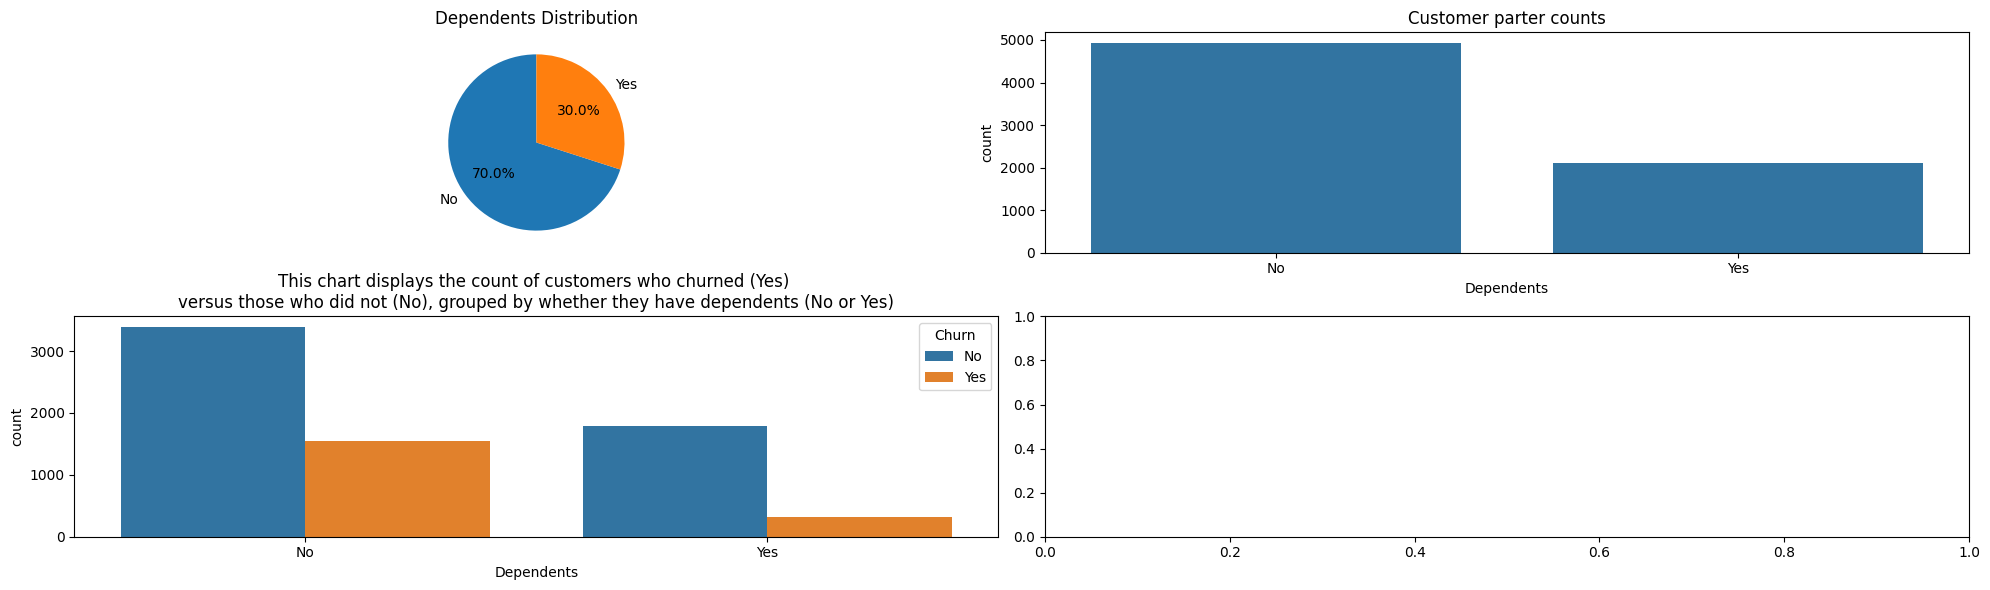

In [36]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['Dependents'].value_counts(), 
            labels=features['Dependents'].value_counts().index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0, 0].set_title('Dependents Distribution')

sns.countplot(data=features, x='Dependents', ax=axes[0, 1])
axes[0, 1].set_title('Customer parter counts')

sns.countplot(data=features, x='Dependents', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('This chart displays the count of customers who churned (Yes) \nversus those who did not (No), grouped by whether they have dependents (No or Yes)')

fig.tight_layout()
plt.show()

In dataset there are 30% of individual who have __Dependents__ and 70% of individual who dont have any __Dependents__

1. Customers without __Dependents__ (No on the left): This is the largest group overall. Roughly 3,400 customers stayed (Churn = No), while over 1,500 churned (Churn = Yes), representing a high churn count and rate.
2. Customers with __Dependents__ (Yes on the right): Fewer customers in the dataset have dependents. Around 1,800 stayed (Churn = No), while only about 300 churned (Churn = Yes), showing a significantly lower churn rate compared to those without dependents.

<br><br>
__Tenure:__ Number of months the customer has stayed with the company

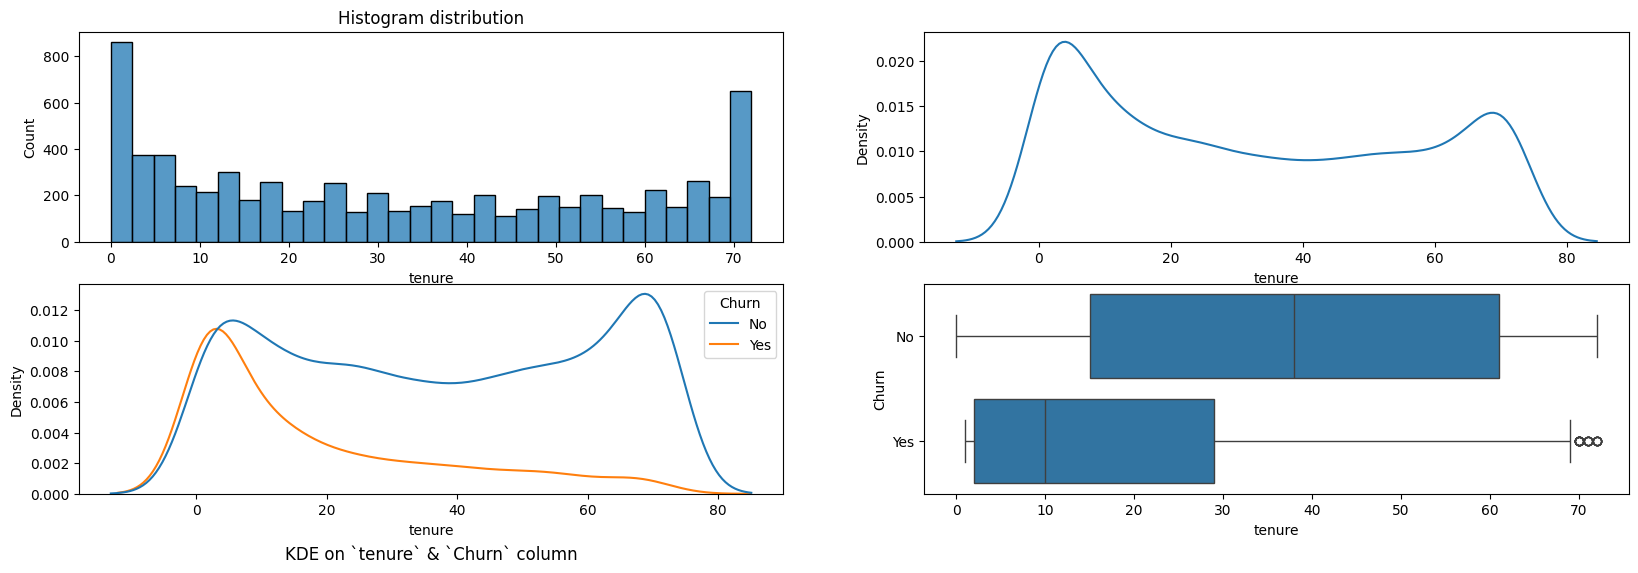

In [84]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

sns.histplot(data=features, x='tenure', bins=30, ax=axes[0, 0])
axes[0, 0].set_title('Histogram distribution')

sns.kdeplot(data=features, x='tenure', ax=axes[0, 1])
axes[0, 0].set_title('Histogram distribution')

sns.kdeplot(data=features, x='tenure', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('KDE on `tenure` & `Churn` column', y=-0.35)

sns.boxplot(data=features, x='tenure', y=target, ax=axes[1, 1])

plt.show()

Histogram displays the row count of customers across different tenure lengths. It highlights a bimodal(2 peak) pattern:
1. __New customers:__ There is a massive spike at the very begining 0-3 months, meaning the company accquires a high volume of new customers.
2. __Loyal customers:__ There is a second major peak near the 70-month mark, showing that a large group of customers stays with the company for a very long time

<br>

__KDE with `tenure` and `Churn` column__
* __High churn at lower tenure(New customers):__ The orange line (churn = yes) has a steep peak at the very begining (between 0 and 10 months). This indicates that new customers are much more likely to churn early on.

* __Lower Tenure equal higher retension:__ The blue line (Churn = No) stays prominent across all tenures and shows a major peak around 70 months. This means customers who stick around for a long time are significantly less likely to churn

In [117]:
features.columns

# features['PhoneService']
# features['MultipleLines']
# features['InternetService']
# features['OnlineSecurity']
# features['OnlineBackup']
# features['DeviceProtection']
# features['TechSupport']
# features['StreamingTV']
# features['StreamingMovies']

# features['Contract'].value_counts()
# features['PaperlessBilling'].value_counts()

# features['PaymentMethod'].value_counts()

# features['MonthlyCharges']

features['TotalCharges']

0         29.85
1        1889.5
2        108.15
3       1840.75
4        151.65
         ...   
7038     1990.5
7039     7362.9
7040     346.45
7041      306.6
7042     6844.5
Name: TotalCharges, Length: 7043, dtype: object